In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from IPython.display import display
%matplotlib inline

def read_fred(path):
    d = pd.read_csv(path)
    v = pd.to_numeric(d.iloc[:, 1], errors="coerce")
    ok = v.notna()
    return pd.to_datetime(d.iloc[:, 0][ok]).reset_index(drop=True), v[ok].to_numpy()

def ar_forecast(y, p, h):
    y = np.array(y, float)
    return AutoReg(y, lags=p, trend="c").fit().predict(start=len(y), end=len(y) + h - 1)

dates, y = read_fred("MRTSSM4453USN.csv")
H, PMAX = 36, 24
train, test = y[:-H], y[-H:]

In [2]:
rows, preds = [], {}
for p in range(1, PMAX + 1):
    preds[p] = ar_forecast(train, p, H)
    rows.append((p, np.mean((test - preds[p]) ** 2)))

mse = pd.DataFrame(rows, columns=["p", "test MSE"]).set_index("p")
best = int(mse["test MSE"].idxmin())
display(mse.round(2))
print(f"Best p = {best}, test MSE = {mse.loc[best, 'test MSE']:.2f}")

,test MSE
p,
1,3973206.80
2,1813321.95
3,652418.38
4,456696.45
5,627553.99
6,722613.69
7,776809.10
8,781310.52
9,806395.38


Best p = 15, test MSE = 260807.03


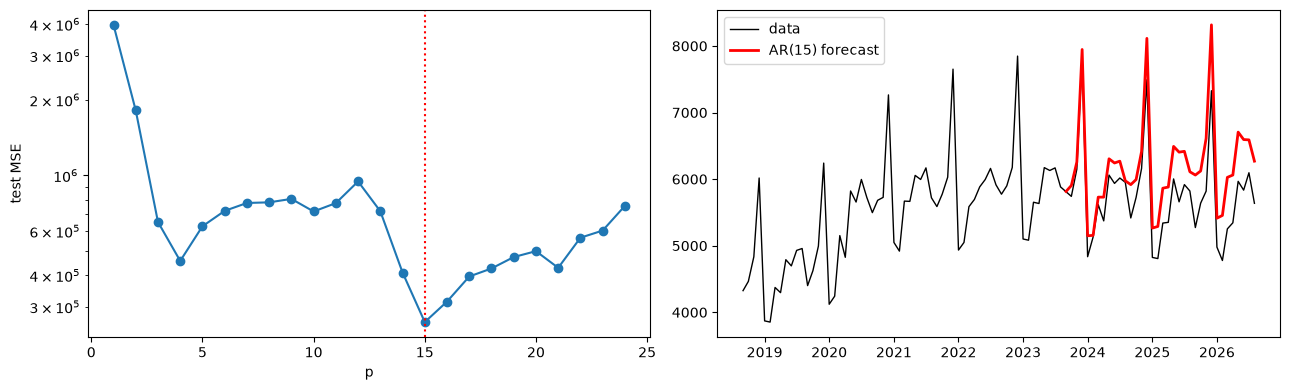

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(mse.index, mse["test MSE"], "o-")
ax[0].axvline(best, ls=":", c="r")
ax[0].set_yscale("log")
ax[0].set_xlabel("p")
ax[0].set_ylabel("test MSE")
td = dates.iloc[-H:]
ax[1].plot(dates.iloc[-96:], y[-96:], "k", lw=1, label="data")
ax[1].plot(td, preds[best], "r", lw=2, label=f"AR({best}) forecast")
ax[1].legend()
plt.tight_layout()
plt.show()

The best model is AR(15). AR(1) is by far the worst. The error drops sharply for the first few values of p, moves around for middle values, and is lowest at p = 15. AR(15) captures the timing of the yearly seasonal peaks, but its forecasts run somewhat above the actual values.